# F1 Data Analytics — ejecución por fases
Ejecuta en orden. Una celda de código por fase. Kafka usa un tópico aislado por ejecución de fase 3, sin borrar mensajes anteriores. HDFS y Spark se reutilizan mientras el entorno exista. Si Colab elimina la VM, se pierden servicios y datos locales; RAW y evidencias de Drive permanecen. La fase 5 sobrescribe su salida curada como en el original. No ejecutar fases simultáneamente.

## Fase 1. Fuente y arquitectura

In [1]:
# --- Paso original 1 ---
import requests
import pandas as pd

url = "https://api.openf1.org/v1/sessions"

parametros = {
    "year": 2024,
    "session_name": "Race"
}

respuesta = requests.get(
    url,
    params=parametros,
    timeout=30
)

respuesta.raise_for_status()

datos = respuesta.json()

df = pd.DataFrame(datos)

print("Estado HTTP:", respuesta.status_code)
print("Cantidad de sesiones:", len(df))

display(df.head())


# --- Paso original 2 ---
import requests
import pandas as pd

url = "https://api.openf1.org/v1/car_data"

parametros = {
    "session_key": 9159,
    "driver_number": 55
}

respuesta = requests.get(
    url,
    params=parametros,
    timeout=120
)

print("Estado HTTP:", respuesta.status_code)

respuesta.raise_for_status()

datos = respuesta.json()

df_prueba = pd.DataFrame(datos)

print("Cantidad de registros:", len(df_prueba))

display(df_prueba.head(10))


# --- Paso original 3 ---
print("URL consultada:", respuesta.url)
print("Tipo de respuesta:", type(datos))
print("Contenido:", datos[:4])


# --- Paso original 4 ---
url = "https://api.openf1.org/v1/car_data"

parametros = {
    "session_key": 9159,
    "driver_number": 1
}

respuesta = requests.get(
    url,
    params=parametros,
    timeout=120
)

respuesta.raise_for_status()

df_piloto2 = pd.DataFrame(respuesta.json())

print("Estado HTTP:", respuesta.status_code)
print("Registros del segundo piloto:", len(df_piloto2))

display(df_piloto2.head())


# --- Paso original 5 ---
df_telemetria = pd.concat(
    [df_prueba, df_piloto2],
    ignore_index=True
)

print("Registros del piloto 55:", len(df_prueba))
print("Registros del piloto 1:", len(df_piloto2))
print("Total de registros:", len(df_telemetria))

display(df_telemetria.head(10))


# --- Paso original 6 ---
columnas_clave = [
    "session_key",
    "driver_number",
    "date"
]

# Comprobar valores nulos en las claves
nulos = df_telemetria[columnas_clave].isna().any(axis=1).sum()

# Crear identificador compuesto
df_telemetria["id_registro"] = (
    df_telemetria["session_key"].astype(str) + "_" +
    df_telemetria["driver_number"].astype(str) + "_" +
    df_telemetria["date"].astype(str)
)

total = len(df_telemetria)

duplicados = df_telemetria.duplicated(
    subset=columnas_clave
).sum()

unicos = df_telemetria.dropna(
    subset=columnas_clave
)["id_registro"].nunique()

print("Total de registros:", total)
print("Registros unicos validos:", unicos)
print("Registros duplicados:", duplicados)
print("Registros con claves nulas:", nulos)

if unicos >= 20000:
    print("La fuente cumple con la guia.")
else:
    print("Se necesitan mas registros.")


# --- Paso original 7 ---
import json
from google.colab import files

resumen = {
    "proyecto": "F1 Data Analytics",
    "fuente": "OpenF1",
    "endpoint": "car_data",
    "session_key": 9159,
    "pilotos": [55, 1],
    "total_registros": int(total),
    "registros_unicos": int(unicos),
    "duplicados": int(duplicados),
    "claves_nulas": int(nulos),
    "cumple_requisito": bool(unicos >= 20000)
}

with open("evidencia_fase_1.json", "w") as archivo:
    json.dump(resumen, archivo, indent=4)

print(json.dumps(resumen, indent=4))

files.download("evidencia_fase_1.json")


# Fase 1. Fuente, pregunta y arquitectura
#
# Fuente de datos: OpenF1.
#
# Endpoint: https://api.openf1.org/v1/car_data
#
# Pregunta principal: ¿Cómo varía el rendimiento de los pilotos de Fórmula 1 según la velocidad, las revoluciones del motor y el uso del acelerador durante una sesión?
#
# Usuarios de los indicadores: Aficionados a la Fórmula 1 y analistas de datos deportivos.
#
# Justificación de la fuente: Se seleccionó OpenF1 porque permite consultar datos reales de telemetría mediante una API pública. La comprobación de la fase 1 verifica si se obtienen al menos 20.000 registros únicos de dos pilotos; consultar la evidencia generada en esta ejecución.
#
# Identificador único: Se utiliza la combinación de session_key, driver_number y date para identificar cada registro de telemetría.
#
# Arquitectura: Se utilizará una arquitectura Lambda, ya que permite procesar datos históricos mediante batch y reproducir los eventos históricos mediante streaming. Los indicadores serán almacenados en SQLite y visualizados mediante Power BI.

Estado HTTP: 200
Cantidad de sesiones: 24


,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
0,9472,Race,Race,2024-03-02T15:00:00+00:00,2024-03-02T17:00:00+00:00,1229,63,Sakhir,36,BRN,Bahrain,Sakhir,03:00:00,2024,False
1,9480,Race,Race,2024-03-09T17:00:00+00:00,2024-03-09T19:00:00+00:00,1230,149,Jeddah,153,KSA,Saudi Arabia,Jeddah,03:00:00,2024,False
2,9488,Race,Race,2024-03-24T04:00:00+00:00,2024-03-24T06:00:00+00:00,1231,10,Melbourne,5,AUS,Australia,Melbourne,11:00:00,2024,False
3,9496,Race,Race,2024-04-07T05:00:00+00:00,2024-04-07T07:00:00+00:00,1232,46,Suzuka,4,JPN,Japan,Suzuka,09:00:00,2024,False
4,9673,Race,Race,2024-04-21T07:00:00+00:00,2024-04-21T09:00:00+00:00,1233,49,Shanghai,53,CHN,China,Shanghai,08:00:00,2024,False


Estado HTTP: 200
Cantidad de registros: 18470


,date,session_key,meeting_key,driver_number,speed,n_gear,drs,throttle,brake,rpm
0,2023-09-15T12:45:02.318000+00:00,9159,1219,55,0,0,0,0,0,0
1,2023-09-15T12:45:02.598000+00:00,9159,1219,55,0,0,0,0,0,0
2,2023-09-15T12:45:02.918000+00:00,9159,1219,55,0,0,0,0,0,0
3,2023-09-15T12:45:03.279000+00:00,9159,1219,55,0,0,0,0,0,0
4,2023-09-15T12:45:03.519000+00:00,9159,1219,55,0,0,0,0,0,0
5,2023-09-15T12:45:03.919000+00:00,9159,1219,55,0,0,0,0,0,0
6,2023-09-15T12:45:04.159000+00:00,9159,1219,55,0,0,0,0,0,0
7,2023-09-15T12:45:04.599000+00:00,9159,1219,55,0,0,0,0,0,0
8,2023-09-15T12:45:04.759000+00:00,9159,1219,55,0,0,0,0,0,0
9,2023-09-15T12:45:05.039000+00:00,9159,1219,55,0,0,0,0,0,0


URL consultada: https://api.openf1.org/v1/car_data?session_key=9159&driver_number=55
Tipo de respuesta: <class 'list'>
Contenido: [{'date': '2023-09-15T12:45:02.318000+00:00', 'session_key': 9159, 'meeting_key': 1219, 'driver_number': 55, 'speed': 0, 'n_gear': 0, 'drs': 0, 'throttle': 0, 'brake': 0, 'rpm': 0}, {'date': '2023-09-15T12:45:02.598000+00:00', 'session_key': 9159, 'meeting_key': 1219, 'driver_number': 55, 'speed': 0, 'n_gear': 0, 'drs': 0, 'throttle': 0, 'brake': 0, 'rpm': 0}, {'date': '2023-09-15T12:45:02.918000+00:00', 'session_key': 9159, 'meeting_key': 1219, 'driver_number': 55, 'speed': 0, 'n_gear': 0, 'drs': 0, 'throttle': 0, 'brake': 0, 'rpm': 0}, {'date': '2023-09-15T12:45:03.279000+00:00', 'session_key': 9159, 'meeting_key': 1219, 'driver_number': 55, 'speed': 0, 'n_gear': 0, 'drs': 0, 'throttle': 0, 'brake': 0, 'rpm': 0}]
Estado HTTP: 200
Registros del segundo piloto: 18470


,date,session_key,meeting_key,driver_number,speed,n_gear,drs,throttle,brake,rpm
0,2023-09-15T12:45:02.318000+00:00,9159,1219,1,0,0,0,0,0,0
1,2023-09-15T12:45:02.598000+00:00,9159,1219,1,0,0,0,0,0,0
2,2023-09-15T12:45:02.918000+00:00,9159,1219,1,0,0,0,0,0,0
3,2023-09-15T12:45:03.279000+00:00,9159,1219,1,0,0,0,0,0,0
4,2023-09-15T12:45:03.519000+00:00,9159,1219,1,0,0,0,0,0,0


Registros del piloto 55: 18470
Registros del piloto 1: 18470
Total de registros: 36940


,date,session_key,meeting_key,driver_number,speed,n_gear,drs,throttle,brake,rpm
0,2023-09-15T12:45:02.318000+00:00,9159,1219,55,0,0,0,0,0,0
1,2023-09-15T12:45:02.598000+00:00,9159,1219,55,0,0,0,0,0,0
2,2023-09-15T12:45:02.918000+00:00,9159,1219,55,0,0,0,0,0,0
3,2023-09-15T12:45:03.279000+00:00,9159,1219,55,0,0,0,0,0,0
4,2023-09-15T12:45:03.519000+00:00,9159,1219,55,0,0,0,0,0,0
5,2023-09-15T12:45:03.919000+00:00,9159,1219,55,0,0,0,0,0,0
6,2023-09-15T12:45:04.159000+00:00,9159,1219,55,0,0,0,0,0,0
7,2023-09-15T12:45:04.599000+00:00,9159,1219,55,0,0,0,0,0,0
8,2023-09-15T12:45:04.759000+00:00,9159,1219,55,0,0,0,0,0,0
9,2023-09-15T12:45:05.039000+00:00,9159,1219,55,0,0,0,0,0,0


Total de registros: 36940
Registros unicos validos: 36940
Registros duplicados: 0
Registros con claves nulas: 0
La fuente cumple con la guia.
{
    "proyecto": "F1 Data Analytics",
    "fuente": "OpenF1",
    "endpoint": "car_data",
    "session_key": 9159,
    "pilotos": [
        55,
        1
    ],
    "total_registros": 36940,
    "registros_unicos": 36940,
    "duplicados": 0,
    "claves_nulas": 0,
    "cumple_requisito": true
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Fase 2. Ingesta RAW y Drive

In [2]:
# --- Paso original 9 ---
from google.colab import drive

drive.mount('/content/drive')


# --- Paso original 10 ---
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/F1_Data_Analytics"
)

carpetas = [
    "raw",
    "curada",
    "servicio",
    "manifiestos",
    "evidencias",
    "kafka",
    "mapreduce",
    "streaming",
    "checkpoint"
]

for carpeta in carpetas:
    (BASE / carpeta).mkdir(
        parents=True,
        exist_ok=True
    )

print("Carpetas creadas correctamente")

for carpeta in BASE.iterdir():
    print(carpeta.name)


# --- Paso original 11 ---
import requests
import time
import json

from datetime import datetime, timezone

API_URL = "https://api.openf1.org/v1/car_data"

def consultar_api(parametros):

    for intento in range(1, 4):

        try:
            respuesta = requests.get(
                API_URL,
                params=parametros,
                timeout=120
            )

            respuesta.raise_for_status()

            datos = respuesta.json()

            if not isinstance(datos, list):
                raise ValueError("Respuesta no valida")

            return datos

        except (requests.RequestException, ValueError) as error:

            print(f"Intento {intento}: {error}")

            time.sleep(10 * intento)

    raise RuntimeError("No se pudo descargar los datos")

print("Funcion de ingesta configurada")


# --- Paso original 12 ---
import uuid

fecha_ingesta = datetime.now(timezone.utc).date().isoformat()

lote = uuid.uuid4().hex[:12]

ruta_raw = (
    BASE / "raw" / "openf1" / "car_data"
    / f"fecha_ingesta={fecha_ingesta}"
)

ruta_raw.mkdir(parents=True, exist_ok=True)

archivo_raw = ruta_raw / f"lote_{lote}.jsonl"

pilotos = [55, 1]

total_raw = 0

consultas = []

with open(archivo_raw, "w", encoding="utf-8") as archivo:

    for piloto in pilotos:

        parametros = {
            "session_key": 9159,
            "driver_number": piloto
        }

        datos = consultar_api(parametros)

        for registro in datos:

            id_registro = (
                f"{registro['session_key']}_"
                f"{registro['driver_number']}_"
                f"{registro['date']}"
            )

            sobre = {
                "fuente": "OpenF1",
                "dataset": "car_data",
                "id_registro": id_registro,
                "fecha_ingesta": fecha_ingesta,
                "payload": registro
            }

            archivo.write(
                json.dumps(sobre, ensure_ascii=False) + "\n"
            )

            total_raw += 1

        consultas.append({
            "parametros": parametros,
            "registros": len(datos)
        })

        print(f"Piloto {piloto}: {len(datos)} registros")

        time.sleep(3)

print("Total RAW:", total_raw)
print("Archivo generado:", archivo_raw)


# --- Paso original 13 ---
manifiesto = {
    "fuente": "OpenF1",
    "dataset": "car_data",
    "url": API_URL,
    "lote": lote,
    "fecha_ingesta": fecha_ingesta,
    "consultas": consultas,
    "total_registros": total_raw,
    "archivo": str(archivo_raw),
    "tamano_bytes": archivo_raw.stat().st_size
}

ruta_manifiesto = (
    BASE / "manifiestos" / f"manifiesto_{lote}.json"
)

with open(ruta_manifiesto, "w", encoding="utf-8") as archivo:

    json.dump(
        manifiesto,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print(json.dumps(manifiesto, indent=4))


# --- Paso original 14 ---
with open(archivo_raw, "r", encoding="utf-8") as archivo:

    cantidad = sum(1 for linea in archivo)

print("Registros descargados:", total_raw)
print("Registros guardados:", cantidad)

print(
    "Tamano del archivo:",
    round(archivo_raw.stat().st_size / 1024**2, 2),
    "MB"
)

assert cantidad == total_raw
assert cantidad >= 20000

print("Validacion RAW correcta")


Mounted at /content/drive
Carpetas creadas correctamente
raw
curada
servicio
manifiestos
evidencias
kafka
mapreduce
streaming
checkpoint
Funcion de ingesta configurada
Piloto 55: 18470 registros
Piloto 1: 18470 registros
Total RAW: 36940
Archivo generado: /content/drive/MyDrive/F1_Data_Analytics/raw/openf1/car_data/fecha_ingesta=2026-11-27/lote_6661944d3472.jsonl
{
    "fuente": "OpenF1",
    "dataset": "car_data",
    "url": "https://api.openf1.org/v1/car_data",
    "lote": "6661944d3472",
    "fecha_ingesta": "2026-11-27",
    "consultas": [
        {
            "parametros": {
                "session_key": 9159,
                "driver_number": 55
            },
            "registros": 18470
        },
        {
            "parametros": {
                "session_key": 9159,
                "driver_number": 1
            },
            "registros": 18470
        }
    ],
    "total_registros": 36940,
    "archivo": "/content/drive/MyDrive/F1_Data_Analytics/raw/openf1/car_data/fe

## Fase 3. Kafka: instalación, producción y consumo

In [3]:
# --- Paso original 15 ---
from pathlib import Path
if not Path('/usr/lib/jvm/java-17-openjdk-amd64/bin/java').exists():
    get_ipython().system('apt-get update -qq')
    get_ipython().system('apt-get install -y openjdk-17-jdk-headless -qq')

    get_ipython().system('java -version')


# --- Paso original 16 ---
from pathlib import Path
if not Path('/content/kafka_2.13-3.9.1/bin/kafka-server-start.sh').exists():
    get_ipython().system('wget -q --show-progress https://archive.apache.org/dist/kafka/3.9.1/kafka_2.13-3.9.1.tgz -O /content/kafka.tgz')

    get_ipython().system('tar -xzf /content/kafka.tgz -C /content')

    get_ipython().system('ls /content/kafka_2.13-3.9.1')


# --- Paso original 17 ---
import os, subprocess, time, socket, re, uuid, base64
from pathlib import Path
KAFKA = '/content/kafka_2.13-3.9.1'
os.environ['KAFKA_HEAP_OPTS'] = '-Xms256m -Xmx512m'
os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-17-openjdk-amd64'
config = f'{KAFKA}/config/kraft/server.properties'
def puerto_abierto(port):
    try:
        with socket.create_connection(('localhost', port), timeout=2): return True
    except OSError: return False

def asegurar_kafka():
    global proceso_kafka
    if not puerto_abierto(9092):
        # UUID válido sin capturar advertencias de Java.
        cluster_id = base64.urlsafe_b64encode(uuid.uuid4().bytes).decode().rstrip('=')
        props = dict(line.strip().split('=',1) for line in Path(config).read_text().splitlines() if '=' in line and not line.lstrip().startswith('#'))
        dirs = props.get('log.dirs','/tmp/kraft-combined-logs').split(',')
        meta = Path(props.get('metadata.log.dir',dirs[0])) / 'meta.properties'
        if not meta.exists():
            subprocess.run([f'{KAFKA}/bin/kafka-storage.sh','format','--ignore-formatted','-t',cluster_id,'-c',config],check=True,timeout=60)
        with open('/content/kafka.log','a') as log:
            proceso_kafka = subprocess.Popen([f'{KAFKA}/bin/kafka-server-start.sh',config],stdout=log,stderr=subprocess.STDOUT,start_new_session=True)
        for _ in range(45):
            if proceso_kafka.poll() is not None: raise RuntimeError('Kafka terminó: revisar /content/kafka.log')
            if puerto_abierto(9092): break
            time.sleep(2)
        else: raise RuntimeError('Kafka no inició')
    subprocess.run([f'{KAFKA}/bin/kafka-topics.sh','--list','--bootstrap-server','localhost:9092'],check=True,timeout=45,capture_output=True)
    print('Kafka disponible')
asegurar_kafka()
TOPIC = 'f1-telemetria-' + lote
TOPIC = 'f1-telemetria-' + lote + '-' + uuid.uuid4().hex[:8]


# --- Paso original 18 ---
get_ipython().system('{KAFKA}/bin/kafka-topics.sh      --create      --if-not-exists      --topic {TOPIC}      --bootstrap-server localhost:9092      --partitions 3      --replication-factor 1')


# --- Paso original 19 ---
get_ipython().system('{KAFKA}/bin/kafka-topics.sh      --describe      --topic {TOPIC}      --bootstrap-server localhost:9092')


# --- Paso original 20 ---
get_ipython().system('pip install kafka-python -q')


# --- Paso original 21 ---
from kafka import KafkaConsumer, TopicPartition
verificador = KafkaConsumer(bootstrap_servers="localhost:9092", enable_auto_commit=False)
partes = [TopicPartition(TOPIC, p) for p in sorted(verificador.partitions_for_topic(TOPIC) or [])]
assert partes, "No existe el tópico"
try:
    assert all(v == 0 for v in verificador.end_offsets(partes).values()), "El tópico ya contiene mensajes. Usa un entorno nuevo para repetir el laboratorio sin duplicarlos."
finally:
    verificador.close()


from kafka import KafkaProducer
import json

productor = KafkaProducer(
    bootstrap_servers="localhost:9092",
    key_serializer=lambda clave: clave.encode("utf-8"),
    value_serializer=lambda valor: json.dumps(
        valor
    ).encode("utf-8"),
    acks="all",
    retries=5,
    enable_idempotence=True
)

enviados = 0
pendientes = []
ids_enviados = set()

with open(archivo_raw, "r", encoding="utf-8") as archivo:

    for linea in archivo:

        registro = json.loads(linea)

        if registro["id_registro"] in ids_enviados:
            raise ValueError("El lote contiene IDs repetidos; revisar RAW antes de publicar")
        ids_enviados.add(registro["id_registro"])

        futuro = productor.send(
            TOPIC,
            key=registro["id_registro"],
            value=registro
        )

        pendientes.append(futuro)

        if len(pendientes) >= 1000:

            for mensaje in pendientes:
                mensaje.get(timeout=60)
                enviados += 1

            pendientes.clear()

            print("Mensajes confirmados:", enviados)

for mensaje in pendientes:
    mensaje.get(timeout=60)
    enviados += 1

productor.flush()
productor.close()

print("\nTotal de mensajes enviados:", enviados)


# --- Paso original 22 ---
from kafka import KafkaConsumer
from collections import Counter

consumidor = KafkaConsumer(
    TOPIC,
    bootstrap_servers="localhost:9092",
    group_id="f1-consumidores-" + TOPIC,
    auto_offset_reset="earliest",
    enable_auto_commit=False,
    consumer_timeout_ms=15000,
    value_deserializer=lambda valor: json.loads(
        valor.decode("utf-8")
    )
)

ruta_consumidor = BASE / "kafka" / "mensajes_consumidos.jsonl"

recibidos = 0
particiones = Counter()

with open(ruta_consumidor, "w", encoding="utf-8") as archivo:

    for mensaje in consumidor:

        archivo.write(
            json.dumps(mensaje.value) + "\n"
        )

        recibidos += 1

        particiones[mensaje.partition] += 1

        if recibidos % 5000 == 0:
            print("Mensajes recibidos:", recibidos)

# Confirmar offsets despues de guardar el archivo

if recibidos > 0:
    consumidor.commit()

consumidor.close()

print("\nTotal recibido:", recibidos)

print("\nDistribucion por particiones:")

for particion, cantidad in sorted(particiones.items()):

    print(f"Particion {particion}: {cantidad}")


# --- Paso original 23 ---
evidencia_kafka = {
    "topico": TOPIC,
    "particiones": 3,
    "grupo_consumidor": "f1-consumidores-" + TOPIC,
    "mensajes_enviados": enviados,
    "mensajes_recibidos": recibidos,
    "distribucion": dict(particiones),
    "validacion": enviados == recibidos == total_raw
}

with open(
    BASE / "evidencias" / "evidencia_fase_3.json",
    "w"
) as archivo:

    json.dump(evidencia_kafka, archivo, indent=4)

print(json.dumps(evidencia_kafka, indent=4))

assert enviados == recibidos == total_raw

print("Validacion Kafka correcta")


# Fase 3. Mensajería con Apache Kafka
#
# En esta fase se utiliza Apache Kafka para enviar y recibir los registros de telemetría obtenidos desde OpenF1. Se crea un tópico llamado f1-telemetria con tres particiones, lo que permite distribuir los mensajes y facilitar su procesamiento en paralelo.
#
# El productor se encarga de leer el archivo JSONL y enviar cada registro utilizando el id_registro como clave. Por otro lado, el consumidor recibe los mensajes mediante un grupo de consumo llamado f1-consumidores.
#
# Si el productor se ejecuta dos veces, Kafka puede almacenar nuevamente los mismos registros. Por esta razón, en la zona curada se eliminarán los duplicados utilizando el identificador único de cada registro.

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.21.1+2-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.21.1+2-1~24.04.1) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.21.1+2-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.21.1+2-1~24.04.1) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.21.1+2-1~24.04.1) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.015s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accura

/tmp/ipykernel_1750/1939105059.py:139: DeprecationWarning: value_deserializer does not implement kafka.serializer.Deserializer
  consumidor = KafkaConsumer(


Mensajes recibidos: 5000
Mensajes recibidos: 10000
Mensajes recibidos: 15000
Mensajes recibidos: 20000
Mensajes recibidos: 25000
Mensajes recibidos: 30000
Mensajes recibidos: 35000

Total recibido: 36940

Distribucion por particiones:
Particion 0: 12403
Particion 1: 12315
Particion 2: 12222
{
    "topico": "f1-telemetria-6661944d3472-f55b8cd3",
    "particiones": 3,
    "grupo_consumidor": "f1-consumidores-f1-telemetria-6661944d3472-f55b8cd3",
    "mensajes_enviados": 36940,
    "mensajes_recibidos": 36940,
    "distribucion": {
        "0": 12403,
        "1": 12315,
        "2": 12222
    },
    "validacion": true
}
Validacion Kafka correcta


## Fase 4. Hadoop, MapReduce y PySpark

In [4]:
# Fase 4 - HDFS y MapReduce

# --- Paso original 26 ---
from pathlib import Path
if not Path('/content/hadoop-3.4.1/bin/hdfs').exists():
    get_ipython().system('wget -q --show-progress https://archive.apache.org/dist/hadoop/common/hadoop-3.4.1/hadoop-3.4.1.tar.gz -O /content/hadoop.tar.gz')

    get_ipython().system('tar -xzf /content/hadoop.tar.gz -C /content')

    get_ipython().system('ls /content/hadoop-3.4.1')


# --- Paso original 27 ---
import os
import subprocess
from pathlib import Path

HADOOP = "/content/hadoop-3.4.1"

java = subprocess.check_output(
    ["readlink", "-f", "/usr/bin/java"],
    text=True
).strip()

JAVA_HOME = str(Path(java).parent.parent)

os.environ["JAVA_HOME"] = JAVA_HOME
os.environ["HADOOP_HOME"] = HADOOP
# Evitar que los diagnósticos JVM contaminen stdout de HDFS.
for variable in ("HADOOP_OPTS", "HADOOP_CLIENT_OPTS"):
    opciones = os.environ.get(variable, "")
    if "-Xlog:os+container=off" not in opciones:
        os.environ[variable] = (opciones + " -Xlog:os+container=off").strip()
os.environ["HADOOP_CONF_DIR"] = f"{HADOOP}/etc/hadoop"

os.environ["PATH"] += (
    f":{HADOOP}/bin:{HADOOP}/sbin"
)

print("JAVA_HOME:", JAVA_HOME)
print("HADOOP_HOME:", HADOOP)

get_ipython().system('hadoop version')


# --- Paso original 28 ---
configuracion = Path(HADOOP) / "etc/hadoop"

core_site = """
<configuration>
    <property>
        <name>fs.defaultFS</name>
        <value>hdfs://localhost:9000</value>
    </property>
</configuration>
"""

hdfs_site = """
<configuration>
    <property>
        <name>dfs.replication</name>
        <value>1</value>
    </property>
    <property>
        <name>dfs.namenode.name.dir</name>
        <value>file:///content/hadoop_data/namenode</value>
    </property>
    <property>
        <name>dfs.datanode.data.dir</name>
        <value>file:///content/hadoop_data/datanode</value>
    </property>
</configuration>
"""

mapred_site = """
<configuration>
    <property>
        <name>mapreduce.framework.name</name>
        <value>local</value>
    </property>
</configuration>
"""

(configuracion / "core-site.xml").write_text(core_site)

(configuracion / "hdfs-site.xml").write_text(hdfs_site)

(configuracion / "mapred-site.xml").write_text(mapred_site)

print("Configuracion de Hadoop correcta")


# --- Paso original 29 ---
import time, socket, subprocess, os
from pathlib import Path
hdfs_bin = f"{HADOOP}/bin/hdfs"
ruta_namenode = Path('/content/hadoop_data/namenode/current/VERSION')
if not ruta_namenode.exists():
    if Path('/content/hadoop_data/datanode/current/VERSION').exists():
        raise RuntimeError('Existe un DataNode previo sin metadatos NameNode. No formatear.')
    subprocess.run([hdfs_bin, 'namenode', '-format', '-nonInteractive'], check=True, timeout=60)

def hdfs_cmd(*args, timeout=25):
    return subprocess.run([hdfs_bin, *args], check=True, timeout=timeout, text=True, capture_output=True).stdout

def asegurar_hdfs(ruta='/'):
    try:
        with socket.create_connection(('localhost',9000), timeout=2): pass
    except OSError:
        subprocess.run([hdfs_bin,'--daemon','start','namenode'], check=True, timeout=30)
    subprocess.run([hdfs_bin,'--daemon','start','datanode'], timeout=30)
    for _ in range(8):
        try:
            reporte = hdfs_cmd('dfsadmin','-report',timeout=8)
            import re
            vivos = re.search(r'Live datanodes \((\d+)\)', reporte)
            if vivos and int(vivos.group(1)) > 0:
                print(hdfs_cmd('dfs','-ls',ruta,timeout=10), flush=True)
                return
        except (subprocess.SubprocessError, OSError): pass
        time.sleep(2)
    raise RuntimeError('HDFS no disponible. Revisar logs en '+HADOOP+'/logs; no formatear.')

asegurar_hdfs()


# --- Paso original 30 ---
ruta_hdfs = (
    "/raw/openf1/car_data/"
    f"fecha_ingesta={fecha_ingesta}"
)

archivo_hdfs = (
    f"{ruta_hdfs}/lote_{lote}.jsonl"
)

# Crear directorio en HDFS

subprocess.run([
    "hdfs", "dfs", "-mkdir", "-p",
    ruta_hdfs
], check=True)

# Guardar el lote consumido desde Kafka

subprocess.run([
    "hdfs", "dfs", "-put", "-f",
    str(ruta_consumidor),
    archivo_hdfs
], check=True)

print("Archivo almacenado en HDFS")

get_ipython().system('hdfs dfs -ls -R /raw')

get_ipython().system('hdfs dfs -du -h /raw')


# --- Paso original 31 ---
asegurar_hdfs()
import json
import re

def es_aviso_java(linea):
    return bool(re.match(r"^\s*\[[^\]]+\]\[warning\]\[os,container\]", linea))

def leer_json_hdfs(ruta):
    resultado = hdfs_cmd('dfs', '-cat', ruta, timeout=120)
    registros, invalidos = [], []
    avisos = vacias = 0
    for numero, linea in enumerate(resultado.splitlines(), 1):
        if not linea.strip():
            vacias += 1
            continue
        if es_aviso_java(linea):
            avisos += 1
            continue
        try:
            registro = json.loads(linea)
            if not isinstance(registro, dict) or 'id_registro' not in registro:
                raise ValueError('Registro sin id_registro')
            registros.append(registro)
        except ValueError as exc:
            invalidos.append((numero, str(exc), linea[:200]))
    print('Avisos Java:', avisos, '| Líneas vacías:', vacias,
          '| Registros inválidos:', len(invalidos))
    if invalidos:
        for detalle in invalidos[:5]:
            print(detalle)
        raise ValueError('HDFS contiene registros inválidos; revisar el JSONL original.')
    return registros

registros_hdfs = leer_json_hdfs(archivo_hdfs)
total_hdfs = len(registros_hdfs)
print('Kafka:', recibidos, '| HDFS:', total_hdfs)
assert total_hdfs == recibidos, 'Diferencia entre Kafka y HDFS'
# Comparar también el contenido exacto con el archivo consumido.
from collections import Counter
with open(ruta_consumidor, encoding='utf-8') as entrada:
    esperado = Counter(json.dumps(json.loads(l), sort_keys=True) for l in entrada if l.strip())
assert Counter(json.dumps(r, sort_keys=True) for r in registros_hdfs) == esperado, 'Contenido Kafka/HDFS diferente'
del esperado
print('Validación HDFS correcta')


# 4.2. Procesamiento con MapReduce

# --- Paso original 33 ---
codigo_mapper = '''
import sys
import json

for linea in sys.stdin:

    registro = json.loads(linea)

    piloto = registro["payload"]["driver_number"]

    print(f"{piloto}\\t1")
'''

ruta_mapper = BASE / "mapreduce" / "mapper.py"

ruta_mapper.write_text(codigo_mapper)

print("Mapper creado correctamente")


# --- Paso original 34 ---
codigo_reducer = '''
import sys

piloto_actual = None
total = 0

for linea in sys.stdin:

    piloto, cantidad = linea.strip().split("\\t")

    cantidad = int(cantidad)

    if piloto_actual == piloto:

        total += cantidad

    else:

        if piloto_actual is not None:

            print(f"{piloto_actual}\\t{total}")

        piloto_actual = piloto
        total = cantidad

if piloto_actual is not None:

    print(f"{piloto_actual}\\t{total}")
'''

ruta_reducer = BASE / "mapreduce" / "reducer.py"

ruta_reducer.write_text(codigo_reducer)

print("Reducer creado correctamente")


# --- Paso original 35 ---
import shutil

shutil.copy(ruta_mapper, "/content/mapper.py")
shutil.copy(ruta_reducer, "/content/reducer.py")

jar = (
    f"{HADOOP}/share/hadoop/tools/lib/"
    "hadoop-streaming-3.4.1.jar"
)

salida_mr = "/resultados/mapreduce/conteo_pilotos"

# Eliminar salida anterior si existe

subprocess.run([
    "hdfs", "dfs", "-rm", "-r", "-f",
    salida_mr
])

# Ejecutar MapReduce

subprocess.run([
    "hadoop", "jar", jar,
    "-files", "/content/mapper.py,/content/reducer.py",
    "-mapper", "python3 mapper.py",
    "-reducer", "python3 reducer.py",
    "-input", archivo_hdfs,
    "-output", salida_mr
], check=True)

print("MapReduce finalizado correctamente")


# --- Paso original 36 ---
get_ipython().system('hdfs dfs -cat {salida_mr}/part-*')


# 4.3. Comparar MapReduce con PySpark

# --- Paso original 38 ---
# Instalar en el mismo Python del notebook, antes de importar PySpark.
get_ipython().run_line_magic('pip', 'install --no-cache-dir pyspark==4.0.1')


# --- Paso original 39 ---
import os, sys, subprocess
from pathlib import Path

# Usar exclusivamente los JAR incluidos en PySpark.
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable

import pyspark
from pyspark.sql import SparkSession
from pyspark import SparkContext
assert pyspark.__version__ == "4.0.1", "Reinicia el entorno y ejecuta desde el inicio"

assert Path(os.environ["JAVA_HOME"], "bin/java").exists()
asegurar_hdfs()

spark = (
    SparkSession.builder.appName("F1_Data_Analytics")
    .master("local[2]")
    .config("spark.driver.memory", "2g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.ansi.enabled", "false")
    .config("spark.hadoop.fs.defaultFS", "hdfs://localhost:9000")
    .config("spark.hadoop.ipc.client.connect.max.retries", "2")
    .config("spark.hadoop.ipc.client.connect.max.retries.on.timeouts", "1")
    .config("spark.hadoop.ipc.client.connect.timeout", "5000")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.0.1")
    .getOrCreate()
)
assert spark.version == pyspark.__version__
print("Version de Spark:", spark.version)
spark.range(5).show()
spark._jvm.java.lang.Thread.currentThread().getContextClassLoader().loadClass(
    "org.apache.spark.sql.kafka010.KafkaSourceProvider")
print("Conector Kafka disponible")
def asegurar_spark():
    try:
        spark.range(1).collect()
    except Exception as exc:
        raise RuntimeError('La JVM de Spark no responde. Si murió, reinicia el entorno y recupera RAW desde Drive.') from exc
    return spark


# --- Paso original 40 ---
asegurar_hdfs()

df_raw_spark = spark.read.json(
    f"hdfs://localhost:9000{archivo_hdfs}"
)

print("Total de registros:", df_raw_spark.count())

df_raw_spark.printSchema()

df_raw_spark.show(5, truncate=False)


# --- Paso original 41 ---
conteo_spark = (
    df_raw_spark
    .groupBy("payload.driver_number")
    .count()
    .orderBy("driver_number")
)

conteo_spark.show()


# --- Paso original 42 ---
resultado_mr = subprocess.check_output(
    ["hdfs", "dfs", "-cat", f"{salida_mr}/part-*"],
    text=True
)

datos_mr = {}

for linea in resultado_mr.strip().splitlines():

    if not linea.strip() or es_aviso_java(linea):
        continue

    piloto, cantidad = linea.split("\t")

    datos_mr[int(piloto)] = int(cantidad)

datos_spark = {
    int(fila["driver_number"]): int(fila["count"])
    for fila in conteo_spark.collect()
}

print("Resultado MapReduce:", datos_mr)
print("Resultado Spark:", datos_spark)

coinciden = datos_mr == datos_spark

print("¿Los resultados coinciden?:", coinciden)

assert coinciden

print("Validacion MapReduce y Spark correcta")


# --- Paso original 43 ---
get_ipython().system('hdfs dfs -ls {salida_mr}')

get_ipython().system('hdfs dfs -cat {salida_mr}/part-*')

conteo_spark.show()

print(conteo_spark.columns)


# --- Paso original 44 ---
print("Total HDFS:", total_hdfs)
print("Total MapReduce:", sum(datos_mr.values()))
print("Total Spark:", sum(datos_spark.values()))

print("MapReduce y Spark coinciden:", datos_mr == datos_spark)


# Conteo HDFS ya validado anteriormente; no repetir lectura.

# --- Paso original 46 ---
print("Resultado MapReduce:", datos_mr)
print("Resultado Spark:", datos_spark)

print("Total Kafka:", recibidos)
print("Total HDFS:", total_hdfs)
print("Total MapReduce:", sum(datos_mr.values()))
print("Total Spark:", sum(datos_spark.values()))

coinciden = (
    datos_mr == datos_spark
    and sum(datos_mr.values()) == total_hdfs
    and total_hdfs == recibidos
)

print("¿Los resultados coinciden?:", coinciden)

assert coinciden, "Los resultados no coinciden"

print("Validacion MapReduce y Spark correcta")


# Fase 4. Data Lake en HDFS y MapReduce
#
# En esta fase se utiliza HDFS para almacenar los registros de telemetría que fueron recibidos mediante Apache Kafka. Los archivos se organizan por fuente, conjunto de datos y fecha de ingesta, guardando un archivo por cada lote.
#
# También se implementa MapReduce utilizando Python. El Mapper se encarga de identificar el número de cada piloto y asignarle un valor de uno, mientras que el Reducer suma estos valores para obtener la cantidad de registros de cada piloto.
#
# Finalmente, se realiza el mismo cálculo utilizando PySpark para comprobar que los dos métodos de procesamiento generan los mismos resultados.

/content/hadoop.tar 100%[===================>] 928.88M  15.8MB/s    in 51s     
bin  include  libexec	      licenses-binary  NOTICE-binary  README.txt  share
etc  lib      LICENSE-binary  LICENSE.txt      NOTICE.txt     sbin
JAVA_HOME: /usr/lib/jvm/java-21-openjdk-amd64
HADOOP_HOME: /content/hadoop-3.4.1
Hadoop 3.4.1
Source code repository https://github.com/apache/hadoop.git -r 4d7825309348956336b8f06a08322b78422849b1
Compiled by mthakur on 2024-10-09T14:57Z
Compiled on platform linux-x86_64
Compiled with protoc 3.23.4
From source with checksum 7292fe9dba5e2e44e3a9f763fce3e680
This command was run using /content/hadoop-3.4.1/share/hadoop/common/hadoop-common-3.4.1.jar
Configuracion de Hadoop correcta

Archivo almacenado en HDFS
drwxr-xr-x   - root supergroup          0 2026-11-27 03:40 /raw/openf1
drwxr-xr-x   - root supergroup          0 2026-11-27 03:40 /raw/openf1/car_data
drwxr-xr-x   - root supergroup          0 2026-11-27 03:40 /raw/openf1/car_data/fecha_ingesta=2026-11-27
-rw-r

## Fase 5. Zona curada Parquet

Found 2 items
drwxr-xr-x   - root supergroup          0 2026-11-27 03:40 /raw
drwxr-xr-x   - root supergroup          0 2026-11-27 03:41 /resultados

Registros originales: 36940
root
 |-- dataset: string (nullable = true)
 |-- fecha_ingesta: string (nullable = true)
 |-- fuente: string (nullable = true)
 |-- id_registro: string (nullable = true)
 |-- payload: struct (nullable = true)
 |    |-- brake: long (nullable = true)
 |    |-- date: string (nullable = true)
 |    |-- driver_number: long (nullable = true)
 |    |-- drs: long (nullable = true)
 |    |-- meeting_key: long (nullable = true)
 |    |-- n_gear: long (nullable = true)
 |    |-- rpm: long (nullable = true)
 |    |-- session_key: long (nullable = true)
 |    |-- speed: long (nullable = true)
 |    |-- throttle: long (nullable = true)

+--------+-------------+------+----------------------------------------+--------------------------------------------------------------------+
|dataset |fecha_ingesta|fuente|id_registro       

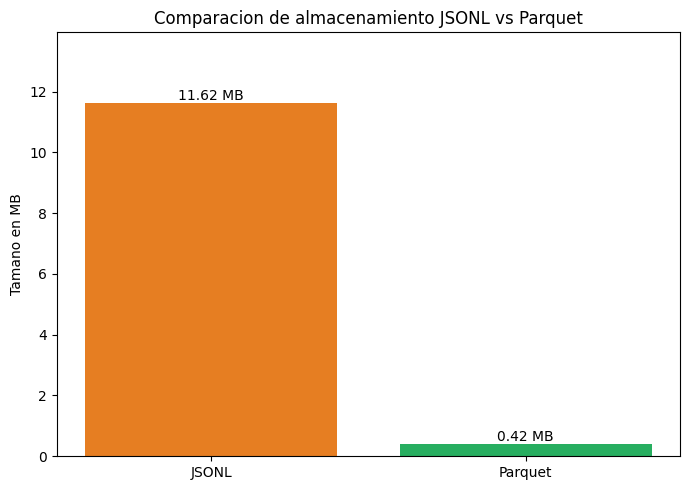

{
    "registros_originales": 36940,
    "nulos_eliminados": 0,
    "duplicados_eliminados": 0,
    "invalidos_eliminados": 7760,
    "total_eliminados": 7760,
    "registros_limpios": 29180,
    "registros_parquet": 29180,
    "tamano_jsonl_mb": 11.62,
    "tamano_parquet_mb": 0.42,
    "reduccion_porcentaje": 96.42,
    "formato": "Parquet",
    "compresion": "Snappy",
    "particiones": [
        "anio",
        "mes"
    ],
    "ruta_parquet": "hdfs://localhost:9000/curada/openf1/car_data",
    "validacion": true
}


In [5]:
asegurar_hdfs()
asegurar_spark()

# Fase 5. Zona curada con PySpark y Parquet

# --- Paso original 49 ---
from pyspark.sql import functions as F

print("Registros originales:", df_raw_spark.count())

df_raw_spark.printSchema()

df_raw_spark.show(5, truncate=False)


# --- Paso original 50 ---
df_plata = df_raw_spark.select(
    "id_registro",
    "fuente",
    "dataset",
    "fecha_ingesta",
    "payload.*"
)

df_plata.show(5)

df_plata.printSchema()


# --- Paso original 51 ---
total_antes = df_plata.count()

print("Total antes de la limpieza:", total_antes)

df_nulos = df_plata.select([
    F.count(
        F.when(F.col(c).isNull(), 1)
    ).alias(c)
    for c in df_plata.columns
])

df_nulos.show(vertical=True)


# --- Paso original 52 ---
spark.conf.set("spark.sql.session.timeZone", "UTC")

df_plata = (
    df_plata
    .withColumn(
        "session_key",
        F.col("session_key").cast("int")
    )
    .withColumn(
        "driver_number",
        F.col("driver_number").cast("int")
    )
    .withColumn(
        "date",
        F.to_timestamp("date")
    )
    .withColumn(
        "fecha_ingesta",
        F.to_date("fecha_ingesta")
    )
    .withColumn("speed", F.col("speed").cast("double"))
    .withColumn("rpm", F.col("rpm").cast("int"))
    .withColumn("throttle", F.col("throttle").cast("double"))
    .withColumn("brake", F.col("brake").cast("int"))
    .withColumn("n_gear", F.col("n_gear").cast("int"))
    .withColumn("drs", F.col("drs").cast("int"))
    .withColumn("fuente", F.lower(F.trim("fuente")))
    .withColumn("dataset", F.lower(F.trim("dataset")))
)

df_plata.printSchema()


# --- Paso original 53 ---
columnas_obligatorias = [
    "id_registro",
    "session_key",
    "driver_number",
    "date",
    "fecha_ingesta",
    "speed",
    "rpm",
    "throttle"
]

antes_nulos = df_plata.count()

df_plata = df_plata.dropna(
    subset=columnas_obligatorias
)

despues_nulos = df_plata.count()

nulos_eliminados = antes_nulos - despues_nulos

print("Registros eliminados por nulos:", nulos_eliminados)


# --- Paso original 54 ---
antes_duplicados = df_plata.count()

df_plata = df_plata.dropDuplicates(
    ["id_registro"]
)

despues_duplicados = df_plata.count()

duplicados_eliminados = (
    antes_duplicados - despues_duplicados
)

print("Registros antes:", antes_duplicados)
print("Registros despues:", despues_duplicados)
print("Duplicados eliminados:", duplicados_eliminados)


# --- Paso original 55 ---
antes_rangos = df_plata.count()

df_plata = df_plata.filter(
    (F.col("speed") >= 0) &
    (F.col("rpm") >= 0) &
    (F.col("throttle").between(0, 100))
)

despues_rangos = df_plata.count()

invalidos_eliminados = (
    antes_rangos - despues_rangos
)

print("Registros invalidos eliminados:", invalidos_eliminados)


# --- Paso original 56 ---
df_plata = (
    df_plata
    .withColumn("fecha_evento", F.to_date("date"))
    .withColumn("anio", F.year("date"))
    .withColumn("mes", F.month("date"))
    .withColumn("dia", F.dayofmonth("date"))
    .withColumn("hora", F.hour("date"))
)

df_plata.show(5, truncate=False)


# --- Paso original 57 ---
total_despues = df_plata.count()

total_eliminados = total_antes - total_despues

porcentaje_conservado = (
    total_despues / total_antes
) * 100

print("----- RESULTADO DE LIMPIEZA -----")

print("Registros originales:", total_antes)
print("Eliminados por nulos:", nulos_eliminados)
print("Duplicados eliminados:", duplicados_eliminados)
print("Valores invalidos eliminados:", invalidos_eliminados)
print("Total eliminados:", total_eliminados)
print("Registros limpios:", total_despues)

print(
    "Porcentaje conservado:",
    round(porcentaje_conservado, 2),
    "%"
)

assert total_eliminados == (
    nulos_eliminados +
    duplicados_eliminados +
    invalidos_eliminados
)


# --- Paso original 58 ---
asegurar_hdfs()

ruta_parquet = (
    "hdfs://localhost:9000"
    "/curada/openf1/car_data"
)

(
    df_plata.write
    .mode("overwrite")
    .option("compression", "snappy")
    .partitionBy("anio", "mes")
    .parquet(ruta_parquet)
)

print("Datos Parquet almacenados correctamente")


# --- Paso original 59 ---
get_ipython().system('hdfs dfs -ls -R /curada')

get_ipython().system('hdfs dfs -du -h /curada')


# --- Paso original 60 ---
asegurar_hdfs()

df_parquet = spark.read.parquet(ruta_parquet)

total_parquet = df_parquet.count()

print("Registros limpios:", total_despues)
print("Registros Parquet:", total_parquet)

df_parquet.show(5)

assert total_parquet == total_despues

print("Validacion Parquet correcta")


# --- Paso original 61 ---
import subprocess
import re

def obtener_tamano_hdfs(ruta):

    resultado = subprocess.check_output(
        ["hdfs", "dfs", "-du", "-s", ruta],
        text=True
    )

    for linea in resultado.splitlines():

        if re.match(r"^\s*\d+\s+\d+\s+", linea):

            return int(linea.split()[0])

    raise ValueError("No se encontro el tamano")


bytes_jsonl = obtener_tamano_hdfs(archivo_hdfs)

bytes_parquet = obtener_tamano_hdfs(ruta_parquet)

mb_jsonl = bytes_jsonl / 1024**2

mb_parquet = bytes_parquet / 1024**2

reduccion = (
    1 - bytes_parquet / bytes_jsonl
) * 100

print("Tamano JSONL:", round(mb_jsonl, 2), "MB")

print("Tamano Parquet:", round(mb_parquet, 2), "MB")

print("Reduccion de almacenamiento:", round(reduccion, 2), "%")


# --- Paso original 62 ---
import matplotlib.pyplot as plt

formatos = ["JSONL", "Parquet"]

tamanos = [mb_jsonl, mb_parquet]

plt.figure(figsize=(7, 5))

barras = plt.bar(
    formatos,
    tamanos,
    color=["#E67E22", "#27AE60"]
)

plt.bar_label(barras, fmt="%.2f MB")

plt.title("Comparacion de almacenamiento JSONL vs Parquet")

plt.ylabel("Tamano en MB")

plt.ylim(0, max(tamanos) * 1.2)

plt.tight_layout()

plt.savefig(
    BASE / "evidencias" / "comparacion_formatos.png",
    dpi=150
)

plt.show()


# --- Paso original 63 ---
import json

evidencia_fase_5 = {
    "registros_originales": total_antes,
    "nulos_eliminados": nulos_eliminados,
    "duplicados_eliminados": duplicados_eliminados,
    "invalidos_eliminados": invalidos_eliminados,
    "total_eliminados": total_eliminados,
    "registros_limpios": total_despues,
    "registros_parquet": total_parquet,
    "tamano_jsonl_mb": round(mb_jsonl, 2),
    "tamano_parquet_mb": round(mb_parquet, 2),
    "reduccion_porcentaje": round(reduccion, 2),
    "formato": "Parquet",
    "compresion": "Snappy",
    "particiones": ["anio", "mes"],
    "ruta_parquet": ruta_parquet,
    "validacion": total_parquet == total_despues
}

with open(
    BASE / "evidencias" / "evidencia_fase_5.json",
    "w"
) as archivo:

    json.dump(
        evidencia_fase_5,
        archivo,
        indent=4
    )

print(json.dumps(evidencia_fase_5, indent=4))


# ### Fase 5. Zona curada con PySpark y Parquet
#
# En esta fase se utiliza PySpark para transformar y limpiar los datos que se encuentran almacenados en HDFS. Primero se revisa la estructura de los registros, se corrigen los tipos de datos y se identifican los valores nulos, duplicados y datos que no cumplen con las reglas establecidas.
#
# Después de realizar la limpieza, los registros se almacenan en formato Parquet con compresión Snappy, organizados por año y mes. Esta organización permite aprovechar mejor el espacio de almacenamiento y facilita las consultas cuando se manejan grandes volúmenes de información.
#
# Finalmente, se compara el tamaño del archivo JSONL con el formato Parquet y se verifica que los registros limpios se hayan almacenado correctamente.

## Fase 6. Calidad e idempotencia

In [8]:
# ============================================================
# FASE 6 - CALIDAD DE DATOS E IDEMPOTENCIA
# PROYECTO: F1 DATA ANALYTICS
# ============================================================

import time
import json

from pyspark import StorageLevel
from pyspark.sql import functions as F

inicio_fase6 = time.time()

# ============================================================
# 6.1 VERIFICACION DE SERVICIOS
# ============================================================

asegurar_hdfs()
asegurar_spark()

spark.conf.set("spark.sql.shuffle.partitions", "4")
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set(
    "spark.sql.adaptive.coalescePartitions.enabled",
    "true"
)

spark.conf.set(
    "spark.sql.sources.partitionOverwriteMode",
    "dynamic"
)

print("=" * 60)
print("FASE 6 - CALIDAD DE DATOS E IDEMPOTENCIA")
print("=" * 60)

print("Configuracion optimizada correctamente")


# ============================================================
# 6.2 CONFIGURACION DE RUTAS
# ============================================================

ruta_parquet = (
    "hdfs://localhost:9000"
    "/curada/openf1/car_data"
)

ruta_incremental = (
    "hdfs://localhost:9000"
    "/curada_incremental/openf1/car_data"
)

ruta_raw = (
    "hdfs://localhost:9000"
    "/raw/openf1/car_data"
)

ruta_watermark = (
    BASE / "checkpoint" / "watermark_batch.json"
)

ruta_evidencias = BASE / "evidencias"

ruta_watermark.parent.mkdir(
    parents=True,
    exist_ok=True
)

ruta_evidencias.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 6.3 REVISION DE DATOS ORIGINALES
# ============================================================

print("\nRevisando datos originales...", flush=True)

df_revision = df_raw_spark.select(
    "id_registro",
    "payload.*"
)

df_revision.agg(

    F.count(
        F.when(F.col("speed") < 0, 1)
    ).alias("velocidad_invalida"),

    F.count(
        F.when(F.col("rpm") < 0, 1)
    ).alias("rpm_invalidas"),

    F.count(
        F.when(
            ~F.col("throttle").between(0, 100),
            1
        )
    ).alias("acelerador_invalido")

).show()

df_revision.groupBy("throttle") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(30)


# ============================================================
# 6.4 FUNCION DE VALIDACION DE CALIDAD
# ============================================================

def validar_calidad(df):

    def contar(condicion):
        return F.count(F.when(condicion, 1))

    resultado = df.agg(

        F.count("*").alias("total_registros"),

        F.countDistinct(
            "id_registro"
        ).alias("ids_distintos"),

        contar(
            F.col("id_registro").isNull() |
            (F.trim("id_registro") == "")
        ).alias("identificadores_nulos"),

        contar(
            F.col("date").isNull() |
            F.col("fecha_ingesta").isNull()
        ).alias("fechas_invalidas"),

        contar(
            F.col("speed").isNull() |
            F.col("rpm").isNull() |
            (F.col("speed") < 0) |
            (F.col("rpm") < 0)
        ).alias("velocidad_rpm_invalidas"),

        contar(
            F.col("throttle").isNull() |
            ~F.col("throttle").between(0, 100)
        ).alias("acelerador_invalido"),

        F.max(
            "fecha_ingesta"
        ).alias("ultima_fecha")

    ).first().asDict()

    total = resultado["total_registros"]

    resultado["duplicados"] = (
        total - resultado.pop("ids_distintos")
    )

    ultima_fecha = resultado.pop("ultima_fecha")

    resultado["calidad_aprobada"] = (
        total > 0 and
        all(
            valor == 0
            for clave, valor in resultado.items()
            if clave != "total_registros"
        )
    )

    resultado["ultima_fecha_procesada"] = (
        str(ultima_fecha)
        if ultima_fecha is not None
        else None
    )

    print(json.dumps(resultado, indent=4))

    if not resultado["calidad_aprobada"]:

        raise ValueError(
            "ERROR CRITICO: procesamiento detenido"
        )

    return resultado


# ============================================================
# 6.5 LECTURA Y VALIDACION DE PARQUET
# ============================================================

asegurar_hdfs("/curada/openf1/car_data")

print("\nLeyendo datos curados...", flush=True)

df_parquet = (
    spark.read.parquet(ruta_parquet)
    .persist(StorageLevel.MEMORY_AND_DISK)
)

reporte_calidad = validar_calidad(df_parquet)

reporte_calidad["registros_originales"] = total_antes

reporte_calidad["registros_descartados"] = total_eliminados

reporte_calidad["motivos_descarte"] = {

    "nulos": nulos_eliminados,

    "duplicados": duplicados_eliminados,

    "fuera_de_rango": invalidos_eliminados

}

reporte_calidad["porcentaje_descartado"] = (

    round(total_eliminados / total_antes * 100, 2)

    if total_antes > 0 else 0

)

with open(
    ruta_evidencias / "reporte_calidad.json",
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        reporte_calidad,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("\nReporte de calidad generado")


# ============================================================
# 6.6 PRUEBA DE DETECCION DE ERRORES
# ============================================================

print("\nProbando deteccion de duplicados...", flush=True)

# Solo utilizar un registro para la prueba
df_muestra = df_parquet.limit(1)

df_prueba_error = df_muestra.unionByName(
    df_muestra
)

error_detectado = False

try:

    validar_calidad(df_prueba_error)

except ValueError as error:

    error_detectado = True

    print("Error detectado correctamente:")
    print(error)

assert error_detectado, (
    "No se detecto el duplicado de prueba"
)


# ============================================================
# 6.7 VERIFICAR CARGA INCREMENTAL ANTERIOR
# ============================================================

def existe_hdfs(ruta):

    jvm = spark._jvm

    path = jvm.org.apache.hadoop.fs.Path(ruta)

    fs = path.getFileSystem(
        spark._jsc.hadoopConfiguration()
    )

    return fs.exists(path)


asegurar_hdfs()

incremental_existe = existe_hdfs(ruta_incremental)

if incremental_existe:

    print("\nRecuperando carga incremental anterior")

    df_existente = (
        spark.read.parquet(ruta_incremental)
        .persist(StorageLevel.MEMORY_AND_DISK)
    )

    estado = df_existente.agg(

        F.count("*").alias("total"),

        F.max("fecha_ingesta").alias("fecha")

    ).first()

    registros_primera_carga = estado.total

    watermark = str(estado.fecha)

else:

    print("\nUtilizando datos curados iniciales")

    df_existente = df_parquet

    registros_primera_carga = (
        reporte_calidad["total_registros"]
    )

    watermark = (
        reporte_calidad["ultima_fecha_procesada"]
    )

assert watermark and watermark != "None", (
    "No existe una fecha de ingesta valida"
)

print("Watermark inicial:", watermark)

print(
    "Registros existentes:",
    registros_primera_carga
)


# ============================================================
# 6.8 FUNCION DE LIMPIEZA
# ============================================================

def limpiar_lote(df):

    df = df.select(

        "id_registro",

        "fuente",

        "dataset",

        "fecha_ingesta",

        "payload.*"

    )

    df = (

        df

        .withColumn(
            "session_key",
            F.col("session_key").cast("int")
        )

        .withColumn(
            "driver_number",
            F.col("driver_number").cast("int")
        )

        .withColumn(
            "date",
            F.to_timestamp("date")
        )

        .withColumn(
            "fecha_ingesta",
            F.to_date("fecha_ingesta")
        )

        .withColumn(
            "speed",
            F.col("speed").cast("double")
        )

        .withColumn(
            "rpm",
            F.col("rpm").cast("int")
        )

        .withColumn(
            "throttle",
            F.col("throttle").cast("double")
        )

        .withColumn(
            "brake",
            F.col("brake").cast("int")
        )

        .withColumn(
            "n_gear",
            F.col("n_gear").cast("int")
        )

        .withColumn(
            "drs",
            F.col("drs").cast("int")
        )

        .withColumn(
            "fuente",
            F.lower(F.trim("fuente"))
        )

        .withColumn(
            "dataset",
            F.lower(F.trim("dataset"))
        )

    )

    df = df.dropna(

        subset=[

            "id_registro",
            "session_key",
            "driver_number",
            "date",
            "fecha_ingesta",
            "speed",
            "rpm",
            "throttle"

        ]

    )

    df = df.filter(

        (F.trim("id_registro") != "") &

        (F.col("speed") >= 0) &

        (F.col("rpm") >= 0) &

        (F.col("throttle").between(0, 100))

    )

    df = df.dropDuplicates(["id_registro"])

    df = (

        df

        .withColumn(
            "fecha_evento",
            F.to_date("date")
        )

        .withColumn(
            "anio",
            F.year("date")
        )

        .withColumn(
            "mes",
            F.month("date")
        )

        .withColumn(
            "dia",
            F.dayofmonth("date")
        )

        .withColumn(
            "hora",
            F.hour("date")
        )

    )

    return df

print("\nFuncion de limpieza configurada")


# ============================================================
# 6.9 LECTURA DEL LOTE INCREMENTAL
# ============================================================

inicio = time.time()

asegurar_hdfs()

print("\nLeyendo lote incremental...", flush=True)

df_raw_incremental = (

    spark.read

    .schema(df_raw_spark.schema)

    .option("recursiveFileLookup", "true")

    .option("pathGlobFilter", "*.jsonl")

    .json(ruta_raw)

)

df_nuevos = df_raw_incremental.filter(

    F.to_date("fecha_ingesta") >=

    F.to_date(F.lit(watermark))

)

df_nuevos_limpios = (

    limpiar_lote(df_nuevos)

    .persist(StorageLevel.MEMORY_AND_DISK)

)

registros_nuevos = df_nuevos_limpios.count()

print("Registros del lote:", registros_nuevos)

print(
    "Tiempo:",
    round(time.time() - inicio, 2),
    "segundos"
)


# ============================================================
# 6.10 PROCESAMIENTO INCREMENTAL OPTIMIZADO
# ============================================================

inicio = time.time()

print("\nProcesando lote incremental...", flush=True)

df_ids = df_existente.select("id_registro")

df_solo_nuevos = (

    df_nuevos_limpios

    .join(

        df_ids,

        on="id_registro",

        how="left_anti"

    )

    .persist(StorageLevel.MEMORY_AND_DISK)

)

cantidad_nuevos = df_solo_nuevos.count()

registros_antes_deduplicar = (

    registros_primera_carga +

    registros_nuevos

)

registros_segunda_carga = (

    registros_primera_carga +

    cantidad_nuevos

)

if cantidad_nuevos == 0:

    df_incremental = df_existente

    print("No hay registros nuevos")

else:

    df_incremental = df_existente.unionByName(
        df_solo_nuevos
    )

print("Primera carga:", registros_primera_carga)

print("Registros del lote:", registros_nuevos)

print("Registros nuevos:", cantidad_nuevos)

print(
    "Duplicados descartados:",
    registros_nuevos - cantidad_nuevos
)

print("Segunda carga:", registros_segunda_carga)

print(
    "Tiempo:",
    round(time.time() - inicio, 2),
    "segundos"
)


# ============================================================
# 6.11 VALIDACION DE IDEMPOTENCIA
# ============================================================

inicio = time.time()

print("\nValidando idempotencia...", flush=True)

ids_incrementales = df_incremental.select(
    "id_registro"
)

idempotencia = (

    df_nuevos_limpios

    .select("id_registro")

    .join(

        ids_incrementales,

        on="id_registro",

        how="left_anti"

    )

    .isEmpty()

)

assert idempotencia, "Error de idempotencia"

print("Idempotencia:", idempotencia)

print(
    "Tiempo:",
    round(time.time() - inicio, 2),
    "segundos"
)


# ============================================================
# 6.12 VALIDACION FINAL
# ============================================================

print("\nValidando calidad final...", flush=True)

# Reutilizar reporte cuando los datos no cambiaron

if cantidad_nuevos == 0 and not incremental_existe:

    reporte_incremental = reporte_calidad.copy()

else:

    reporte_incremental = validar_calidad(
        df_incremental
    )

assert (
    reporte_incremental["total_registros"] ==
    registros_segunda_carga
), "La cantidad final de registros no coincide"


# ============================================================
# 6.13 GUARDAR RESULTADOS INCREMENTALES
# ============================================================

inicio = time.time()

asegurar_hdfs()

print("\nGuardando resultados...", flush=True)

if not incremental_existe:

    # Primera escritura: crear zona incremental completa

    (

        df_incremental.write

        .mode("errorifexists")

        .partitionBy("anio", "mes")

        .parquet(ruta_incremental)

    )

    print("Zona incremental creada correctamente")

elif cantidad_nuevos > 0:

    # Guardar solamente los registros nuevos

    (

        df_solo_nuevos.write

        .mode("append")

        .partitionBy("anio", "mes")

        .parquet(ruta_incremental)

    )

    print("Registros nuevos almacenados")

else:

    # Evitar escribir nuevamente los mismos datos

    print("Escritura omitida: no hay cambios")

spark.catalog.refreshByPath(ruta_incremental)

print(
    "Tiempo de escritura:",
    round(time.time() - inicio, 2),
    "segundos"
)

print("Ruta incremental:", ruta_incremental)


# ============================================================
# 6.14 ACTUALIZAR WATERMARK
# ============================================================

control = {

    "dataset": "car_data",

    "ultima_fecha_procesada": (
        reporte_incremental["ultima_fecha_procesada"]
    ),

    "registros_procesados": registros_segunda_carga

}

ruta_watermark.write_text(

    json.dumps(control, indent=4),

    encoding="utf-8"

)

print("\nWatermark actualizado")

print(json.dumps(control, indent=4))


# ============================================================
# 6.15 GENERAR EVIDENCIAS
# ============================================================

tiempo_total = time.time() - inicio_fase6

evidencia_fase_6 = {

    "validaciones_calidad": reporte_calidad,

    "error_critico_detectado": error_detectado,

    "watermark_inicial": watermark,

    "watermark": control["ultima_fecha_procesada"],

    "primera_carga": registros_primera_carga,

    "registros_lote": registros_nuevos,

    "registros_nuevos": cantidad_nuevos,

    "antes_deduplicacion": registros_antes_deduplicar,

    "duplicados_eliminados": (

        registros_antes_deduplicar -

        registros_segunda_carga

    ),

    "segunda_carga": registros_segunda_carga,

    "idempotencia": idempotencia,

    "ruta_incremental": ruta_incremental,

    "calidad_final": reporte_incremental,

    "tiempo_segundos": round(tiempo_total, 2),

    "tiempo_minutos": round(tiempo_total / 60, 2)

}

with open(

    ruta_evidencias / "evidencia_fase_6.json",

    "w",

    encoding="utf-8"

) as archivo:

    json.dump(

        evidencia_fase_6,

        archivo,

        indent=4,

        ensure_ascii=False

    )

print("\nEVIDENCIA FASE 6")

print(json.dumps(evidencia_fase_6, indent=4))


# ============================================================
# 6.16 LIBERAR MEMORIA
# ============================================================

df_solo_nuevos.unpersist()

df_nuevos_limpios.unpersist()

df_existente.unpersist()

df_parquet.unpersist()


# ============================================================
# 6.17 RESULTADOS FINALES
# ============================================================

print("\n" + "=" * 60)

print("FASE 6 FINALIZADA CORRECTAMENTE")

print("=" * 60)

print("Primera carga:", registros_primera_carga)

print("Registros nuevos:", cantidad_nuevos)

print("Segunda carga:", registros_segunda_carga)

print("Idempotencia:", idempotencia)

print("Calidad:", reporte_incremental["calidad_aprobada"])

print("Ruta incremental:", ruta_incremental)

print(
    "Tiempo total:",
    round(tiempo_total, 2),
    "segundos"
)

print(
    "Tiempo en minutos:",
    round(tiempo_total / 60, 2)
)

print("=" * 60)

Found 3 items
drwxr-xr-x   - root supergroup          0 2026-11-27 03:44 /curada
drwxr-xr-x   - root supergroup          0 2026-11-27 03:40 /raw
drwxr-xr-x   - root supergroup          0 2026-11-27 03:41 /resultados

FASE 6 - CALIDAD DE DATOS E IDEMPOTENCIA
Configuracion optimizada correctamente

Revisando datos originales...
+------------------+-------------+-------------------+
|velocidad_invalida|rpm_invalidas|acelerador_invalido|
+------------------+-------------+-------------------+
|                 0|            0|               7760|
+------------------+-------------+-------------------+

+--------+-----+
|throttle|count|
+--------+-----+
|       0|12014|
|     104| 7760|
|     100| 3763|
|      99| 1740|
|       1|  611|
|       2|  340|
|       3|  259|
|      12|  255|
|      29|  237|
|      16|  232|
|      14|  228|
|      30|  220|
|      20|  218|
|      25|  216|
|      32|  208|
|      37|  203|
|      23|  193|
|      21|  191|
|      18|  188|
|      39|  184|
|    

In [ ]:
df_existente.unpersist()
df_nuevos_limpios.unpersist()
df_solo_nuevos.unpersist()

tiempo_total = time.time() - inicio_fase6

print("=" * 50)
print("FASE 6 FINALIZADA")
print("=" * 50)

print(
    "Tiempo total:",
    round(tiempo_total, 2),
    "segundos"
)

print(
    "Tiempo en minutos:",
    round(tiempo_total / 60, 2)
)

## Fase 7. Structured Streaming y recuperación

In [9]:
asegurar_hdfs()
asegurar_spark()

asegurar_kafka()

# Fase 7 - Spark Structured Streaming

# --- Paso original 80 ---
get_ipython().system('jps')

get_ipython().system('{KAFKA}/bin/kafka-topics.sh --bootstrap-server localhost:9092 --describe --topic {TOPIC}')


# --- Paso original 81 ---
import pyspark

print("Version de PySpark:", pyspark.__version__)
print("Version de Spark:", spark.version)


# --- Paso original 82 ---
# Reutilizar la sesión inicial: el conector Kafka ya está cargado.
assert spark.version == "4.0.1"
print("Spark configurado para Kafka:", spark.version)


# --- Paso original 83 ---
asegurar_hdfs()

df_raw_spark = spark.read.json(
    f"hdfs://localhost:9000{archivo_hdfs}"
)

esquema_streaming = df_raw_spark.schema

print("Registros RAW:", df_raw_spark.count())

df_raw_spark.printSchema()


# --- Paso original 84 ---
df_kafka_stream = (
    spark.readStream
    .format("kafka")
    .option(
        "kafka.bootstrap.servers",
        "localhost:9092"
    )
    .option("subscribe", TOPIC)
    .option("startingOffsets", "earliest")
    .option("failOnDataLoss", "true")
    .load()
)

df_kafka_stream.printSchema()

print("Es Streaming:", df_kafka_stream.isStreaming)


# --- Paso original 85 ---
from pyspark.sql import functions as F

df_stream_json = (
    df_kafka_stream
    .selectExpr("CAST(value AS STRING) AS mensaje")
    .select(
        F.from_json(
            F.col("mensaje"),
            esquema_streaming
        ).alias("registro")
    )
    .select("registro.*")
)

df_stream_json.printSchema()


# --- Paso original 86 ---
df_stream_limpio = (
    df_stream_json
    .select(
        "id_registro",
        "fecha_ingesta",
        "payload.*"
    )
    .withColumn("date", F.to_timestamp("date"))
    .withColumn("driver_number", F.col("driver_number").cast("int"))
    .withColumn("session_key", F.col("session_key").cast("int"))
    .withColumn("speed", F.col("speed").cast("double"))
    .withColumn("rpm", F.col("rpm").cast("int"))
    .withColumn("throttle", F.col("throttle").cast("double"))
    .dropna(
        subset=[
            "id_registro",
            "date",
            "driver_number",
            "session_key",
            "speed",
            "rpm",
            "throttle"
        ]
    )
    .filter(
        (F.col("speed") >= 0) &
        (F.col("rpm") >= 0) &
        (F.col("throttle").between(0, 100))
    )
)

df_stream_limpio.printSchema()


# --- Paso original 87 ---
df_ventanas = (
    df_stream_limpio
    .withWatermark("date", "2 minutes")
    .groupBy(
        F.window("date", "1 minute"),
        "session_key",
        "driver_number"
    )
    .agg(
        F.count("*").alias("total_mediciones"),

        F.round(
            F.avg("speed"), 2
        ).alias("velocidad_promedio"),

        F.max("speed").alias("velocidad_maxima"),

        F.round(
            F.avg("rpm"), 2
        ).alias("rpm_promedio"),

        F.round(
            F.avg("throttle"), 2
        ).alias("acelerador_promedio")
    )
    .select(
        F.col("window.start").alias("inicio_ventana"),
        F.col("window.end").alias("fin_ventana"),
        "session_key",
        "driver_number",
        "total_mediciones",
        "velocidad_promedio",
        "velocidad_maxima",
        "rpm_promedio",
        "acelerador_promedio"
    )
)

df_ventanas.printSchema()


# 7.2. Ejecutar el procesamiento en streaming

# --- Paso original 89 ---
ruta_streaming = (
    "hdfs://localhost:9000"
    "/streaming/openf1/indicadores/" + TOPIC
)

ruta_checkpoint_stream = (
    "hdfs://localhost:9000"
    "/checkpoint/f1_streaming/" + TOPIC
)

print("Ruta de resultados:", ruta_streaming)
print("Ruta del checkpoint:", ruta_checkpoint_stream)


# --- Paso original 90 ---
asegurar_hdfs()

query = (
    df_ventanas.writeStream
    .format("parquet")
    .outputMode("append")
    .option("path", ruta_streaming)
    .option(
        "checkpointLocation",
        ruta_checkpoint_stream
    )
    .trigger(availableNow=True)
    .start()
)

if not query.awaitTermination(300):
    query.stop()
    raise TimeoutError("Streaming excedió 300 segundos; revisar progreso y servicios")

print("Procesamiento streaming finalizado")


# --- Paso original 91 ---
df_resultado_stream = spark.read.parquet(
    ruta_streaming
)

df_resultado_stream.orderBy(
    "inicio_ventana",
    "driver_number"
).show(20, truncate=False)

ventanas_primera_ejecucion = (
    df_resultado_stream.count()
)

mediciones_primera_ejecucion = (
    df_resultado_stream
    .agg(F.sum("total_mediciones"))
    .first()[0]
)

print(
    "Ventanas generadas:",
    ventanas_primera_ejecucion
)

print(
    "Mediciones procesadas en ventanas cerradas:",
    mediciones_primera_ejecucion
)


# --- Paso original 92 ---
import json

progreso_primera = query.recentProgress

for progreso in progreso_primera:

    print("Microbatch:", progreso["batchId"])

    print(
        "Registros recibidos:",
        progreso["numInputRows"]
    )

    print(
        "Tiempo de evento:",
        progreso.get("eventTime", {})
    )

    print(
        "Estado:",
        progreso.get("stateOperators", [])
    )

    print("-" * 40)


# --- Paso original 93 ---
get_ipython().system('hdfs dfs -ls -R /checkpoint/f1_streaming')


# 7.3. Prueba de recuperación después de un reinicio

# --- Paso original 95 ---
asegurar_hdfs()

query_reinicio = (
    df_ventanas.writeStream
    .format("parquet")
    .outputMode("append")
    .option("path", ruta_streaming)
    .option(
        "checkpointLocation",
        ruta_checkpoint_stream
    )
    .trigger(availableNow=True)
    .start()
)

if not query_reinicio.awaitTermination(300):
    query_reinicio.stop()
    raise TimeoutError("Streaming excedió 300 segundos; revisar progreso y servicios")

print("Streaming reiniciado correctamente")


# --- Paso original 96 ---
df_stream_reinicio = spark.read.parquet(
    ruta_streaming
)

ventanas_segunda_ejecucion = (
    df_stream_reinicio.count()
)

mediciones_segunda_ejecucion = (
    df_stream_reinicio
    .agg(F.sum("total_mediciones"))
    .first()[0]
)

duplicados_stream = (
    df_stream_reinicio.count() -
    df_stream_reinicio.select(
        "session_key",
        "driver_number",
        "inicio_ventana",
        "fin_ventana"
    ).distinct().count()
)

mensajes_reinicio = sum(
    p["numInputRows"]
    for p in query_reinicio.recentProgress
)

recuperacion_correcta = (
    ventanas_primera_ejecucion > 0
    and ventanas_primera_ejecucion ==
    ventanas_segunda_ejecucion
    and mediciones_primera_ejecucion ==
    mediciones_segunda_ejecucion
    and duplicados_stream == 0
    and mensajes_reinicio == 0
)

print(
    "Ventanas primera ejecucion:",
    ventanas_primera_ejecucion
)

print(
    "Ventanas segunda ejecucion:",
    ventanas_segunda_ejecucion
)

print("Duplicados:", duplicados_stream)

print("Mensajes leidos en reinicio:", mensajes_reinicio)

print(
    "Recuperacion correcta:",
    recuperacion_correcta
)

assert recuperacion_correcta


# --- Paso original 97 ---
evidencia_fase_7 = {
    "fuente_streaming": "Apache Kafka",
    "topic": TOPIC,
    "tipo_streaming": "Reproduccion de datos historicos",
    "ventana": "1 minuto",
    "watermark": "2 minutos",
    "modo_salida": "append",
    "trigger": "availableNow",
    "mensajes_primera_ejecucion": sum(
        p["numInputRows"]
        for p in progreso_primera
    ),
    "ventanas_primera_ejecucion": (
        ventanas_primera_ejecucion
    ),
    "ventanas_segunda_ejecucion": (
        ventanas_segunda_ejecucion
    ),
    "mediciones_primera_ejecucion": (
        mediciones_primera_ejecucion
    ),
    "mediciones_segunda_ejecucion": (
        mediciones_segunda_ejecucion
    ),
    "mensajes_leidos_reinicio": mensajes_reinicio,
    "duplicados": duplicados_stream,
    "ruta_resultados": ruta_streaming,
    "ruta_checkpoint": ruta_checkpoint_stream,
    "recuperacion_correcta": recuperacion_correcta
}

with open(
    BASE / "evidencias" / "evidencia_fase_7.json",
    "w"
) as archivo:

    json.dump(
        evidencia_fase_7,
        archivo,
        indent=4
    )

print(json.dumps(evidencia_fase_7, indent=4))


# Fase 7. Spark Structured Streaming
#
# En esta fase se implementó el procesamiento de datos en streaming utilizando Apache Kafka y Spark Structured Streaming. Se utilizaron los mensajes históricos de telemetría para simular la llegada de información en tiempo real.
#
# Los datos se agruparon en ventanas de un minuto para calcular indicadores como la velocidad promedio, velocidad máxima, revoluciones del motor y porcentaje de uso del acelerador.
#
# También se configuró un watermark de dos minutos para controlar los datos atrasados y un checkpoint para guardar el progreso del procesamiento. Finalmente, se reinició la consulta utilizando el mismo checkpoint para comprobar que los mensajes ya procesados no se volvieran a leer ni generaran resultados duplicados.
#
# Nota: en modo append solo se publican ventanas cerradas por el watermark. Las últimas ventanas pueden quedar pendientes al terminar la reproducción histórica.

Found 4 items
drwxr-xr-x   - root supergroup          0 2026-11-27 03:44 /curada
drwxr-xr-x   - root supergroup          0 2026-11-27 03:58 /curada_incremental
drwxr-xr-x   - root supergroup          0 2026-11-27 03:40 /raw
drwxr-xr-x   - root supergroup          0 2026-11-27 03:41 /resultados

Kafka disponible
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
13267 DataNode
15159 Jps
3096 Kafka
13193 NameNode
7081 SparkSubmit
Topic: f1-telemetria-6661944d3472-f55b8cd3	TopicId: 7Q-tYrWtRPmdeEmfGQNWUw	PartitionCount: 3	ReplicationFactor: 1	Configs: segment.bytes=1073741824
	Topic: f1-telemetria-6661944d3472-f55b8cd3	Partition: 0	Leader: 1	Replicas: 1	Isr: 1	Elr: 	LastKnownElr: 
	Topic: f1-telemetria-6661944d3472-

## Fase 8. Servicio, tablero y repositorio
Ejecutar después de las fases 6 y 7. Consolida ventanas con prioridad Batch para claves coincidentes (no fusiona mediciones de ventanas parciales). Genera SQLite, CSV, evidencias y un tablero HTML autónomo en Drive. No publica un repositorio remoto ni un servicio en vivo.

In [10]:
# ============================================================
# FASE 8 - SERVICIO, TABLERO Y REPOSITORIO
# PROYECTO: F1 DATA ANALYTICS
# ============================================================

import subprocess
import sqlite3
import json
import pandas as pd
import plotly.express as px
import plotly.io as pio

from pathlib import Path
from datetime import datetime, timezone
from pyspark.sql import functions as F
from html import escape


# ============================================================
# 8.1 CONFIGURACION DE RUTAS
# ============================================================

BASE = Path("/content/drive/MyDrive/F1_Data_Analytics")

ruta_servicio = BASE / "servicio"
ruta_dashboard = BASE / "dashboard"
ruta_evidencias = BASE / "evidencias"

for carpeta in [
    ruta_servicio,
    ruta_dashboard,
    ruta_evidencias
]:
    carpeta.mkdir(parents=True, exist_ok=True)

ruta_db = ruta_servicio / "f1_analytics.db"

ruta_curada = ruta_incremental

# Reutilizar ruta_streaming de la fase 7 (específica del tópico).
asegurar_hdfs()
spark = asegurar_spark()
for ruta in (ruta_curada, ruta_streaming):
    comprobacion = subprocess.run(["hdfs", "dfs", "-test", "-e", ruta], timeout=30)
    if comprobacion.returncode != 0:
        raise RuntimeError(f"No existe {ruta}. Ejecuta las fases 6 y 7 primero.")

spark.conf.set("spark.sql.session.timeZone", "UTC")

print("=" * 60)
print("FASE 8 - ZONA DE SERVICIO")
print("=" * 60)


# ============================================================
# 8.2 LECTURA DE DATOS CURADOS
# ============================================================

df_servicio = spark.read.parquet(ruta_curada)

total_curados = df_servicio.count()

assert total_curados > 0, "No existen datos curados"

print("Registros curados:", total_curados)

df_servicio.printSchema()


# ============================================================
# 8.3 CALCULO DE INDICADORES POR PILOTO
# ============================================================

def nombre_piloto():

    return (
        F.when(
            F.col("driver_number") == 55,
            "Carlos Sainz"
        )
        .when(
            F.col("driver_number") == 1,
            "Max Verstappen"
        )
        .otherwise(
            F.concat(
                F.lit("Piloto "),
                F.col("driver_number").cast("string")
            )
        )
    )


df_indicadores = (
    df_servicio
    .groupBy("session_key", "driver_number")
    .agg(
        F.count("*").alias("total_mediciones"),

        F.round(
            F.avg("speed"), 2
        ).alias("velocidad_promedio"),

        F.max("speed").alias("velocidad_maxima"),

        F.min("speed").alias("velocidad_minima"),

        F.round(
            F.avg("rpm"), 2
        ).alias("rpm_promedio"),

        F.max("rpm").alias("rpm_maximo"),

        F.round(
            F.avg("throttle"), 2
        ).alias("acelerador_promedio"),

        F.min("date").alias("fecha_inicio"),

        F.max("date").alias("fecha_corte")
    )
    .withColumn("piloto", nombre_piloto())
)

df_indicadores = df_indicadores.persist()
print("\nINDICADORES POR PILOTO")

df_indicadores.show(truncate=False)


# ============================================================
# 8.4 INDICADORES BATCH POR VENTANA DE TIEMPO
# ============================================================

df_historico = (
    df_servicio
    .groupBy(
        F.window("date", "1 minute"),
        "session_key",
        "driver_number"
    )
    .agg(
        F.count("*").alias("total_mediciones"),

        F.round(
            F.avg("speed"), 2
        ).alias("velocidad_promedio"),

        F.max("speed").alias("velocidad_maxima"),

        F.round(
            F.avg("rpm"), 2
        ).alias("rpm_promedio"),

        F.round(
            F.avg("throttle"), 2
        ).alias("acelerador_promedio")
    )
    .select(
        F.col("window.start").alias("inicio_ventana"),
        F.col("window.end").alias("fin_ventana"),
        "session_key",
        "driver_number",
        "total_mediciones",
        "velocidad_promedio",
        "velocidad_maxima",
        "rpm_promedio",
        "acelerador_promedio"
    )
)

df_historico = df_historico.persist()
total_batch = df_historico.count()
print("\nVentanas batch:", total_batch)


# ============================================================
# 8.5 INTEGRACION BATCH Y STREAMING - LAMBDA
# ============================================================

df_stream_servicio = spark.read.parquet(
    ruta_streaming
)

claves_ventana = [
    "session_key",
    "driver_number",
    "inicio_ventana",
    "fin_ventana"
]

df_stream_servicio = df_stream_servicio.persist()
total_streaming = df_stream_servicio.count()

duplicados_streaming = (
    total_streaming -
    df_stream_servicio
    .select(*claves_ventana)
    .distinct()
    .count()
)

assert duplicados_streaming == 0, (
    "Existen ventanas duplicadas en streaming"
)

# Seleccionar ventanas que no existen en batch

df_stream_nuevo = (
    df_stream_servicio
    .join(
        df_historico.select(*claves_ventana),
        on=claves_ventana,
        how="left_anti"
    )
)

# Consolidar ambas capas

df_lambda = (
    df_historico
    .withColumn("capa", F.lit("Batch"))
    .unionByName(
        df_stream_nuevo.withColumn(
            "capa",
            F.lit("Streaming")
        )
    )
    .withColumn("piloto", nombre_piloto())
)

df_lambda = df_lambda.persist()
total_lambda = df_lambda.count()

duplicados_lambda = (
    total_lambda -
    df_lambda
    .select(*claves_ventana)
    .distinct()
    .count()
)

assert duplicados_lambda == 0, (
    "ERROR: existen ventanas duplicadas"
)

print("\nRESULTADOS ARQUITECTURA LAMBDA")
print("Ventanas batch:", total_batch)
print("Ventanas streaming:", total_streaming)
print("Ventanas nuevas:", df_stream_nuevo.count())
print("Ventanas consolidadas:", total_lambda)
print("Duplicados:", duplicados_lambda)

df_lambda.groupBy("capa").count().show()


# ============================================================
# 8.6 CREACION DE LA BASE DE DATOS SQLITE
# ============================================================

pdf_indicadores = df_indicadores.toPandas()
pdf_lambda = df_lambda.toPandas()
pdf_streaming = df_stream_servicio.toPandas()

with sqlite3.connect(str(ruta_db)) as conexion:

    pdf_indicadores.to_sql(
        "indicadores_pilotos",
        conexion,
        if_exists="replace",
        index=False
    )

    pdf_lambda.to_sql(
        "indicadores_minuto",
        conexion,
        if_exists="replace",
        index=False
    )

    pdf_streaming.to_sql(
        "indicadores_streaming",
        conexion,
        if_exists="replace",
        index=False
    )

    conexion.execute("""
        CREATE UNIQUE INDEX IF NOT EXISTS idx_pilotos
        ON indicadores_pilotos (
            session_key,
            driver_number
        )
    """)

    conexion.execute("""
        CREATE UNIQUE INDEX IF NOT EXISTS idx_ventanas
        ON indicadores_minuto (
            session_key,
            driver_number,
            inicio_ventana,
            fin_ventana
        )
    """)

print("\nBase de datos SQLite creada correctamente")
print("Ubicacion:", ruta_db)


# ============================================================
# 8.7 CONSULTAS A LA ZONA DE SERVICIO
# ============================================================

with sqlite3.connect(str(ruta_db)) as conexion:

    datos_pilotos = pd.read_sql_query("""
        SELECT *
        FROM indicadores_pilotos
        ORDER BY velocidad_promedio DESC
    """, conexion)

    datos_minuto = pd.read_sql_query("""
        SELECT *
        FROM indicadores_minuto
        ORDER BY inicio_ventana
    """, conexion)

    datos_streaming = pd.read_sql_query("""
        SELECT *
        FROM indicadores_streaming
        ORDER BY inicio_ventana
    """, conexion)

    resumen = pd.read_sql_query("""
        SELECT
            COUNT(DISTINCT driver_number) AS pilotos,
            SUM(total_mediciones) AS registros,
            MAX(velocidad_maxima) AS velocidad_maxima,
            MAX(fecha_corte) AS fecha_corte
        FROM indicadores_pilotos
    """, conexion).iloc[0]

print("\nDATOS CONSULTADOS DESDE SQLITE")

print(datos_pilotos.to_string(index=False))

total_pilotos = int(resumen["pilotos"])
total_registros = int(resumen["registros"])
velocidad_maxima = float(resumen["velocidad_maxima"])
fecha_corte = str(resumen["fecha_corte"])


# ============================================================
# 8.8 CREACION DE GRAFICOS INTERACTIVOS
# ============================================================

colores = {
    "Carlos Sainz": "#FF4141",
    "Max Verstappen": "#477BFF"
}

def configurar_grafico(fig):

    fig.update_layout(
        template="plotly_dark",
        paper_bgcolor="#191B24",
        plot_bgcolor="#191B24",
        font=dict(
            family="Arial",
            color="#FFFFFF"
        ),
        margin=dict(
            l=40,
            r=25,
            t=65,
            b=40
        ),
        height=360,
        legend_title_text="Piloto"
    )

    return fig


# Grafico 1 - Velocidad promedio

fig_velocidad = px.bar(
    datos_pilotos,
    x="piloto",
    y="velocidad_promedio",
    color="piloto",
    text_auto=".2f",
    color_discrete_map=colores,
    title="Velocidad promedio por piloto",
    labels={
        "piloto": "Piloto",
        "velocidad_promedio": "Velocidad (km/h)"
    }
)

fig_velocidad = configurar_grafico(fig_velocidad)


# Grafico 2 - Velocidad maxima

fig_maxima = px.bar(
    datos_pilotos,
    x="piloto",
    y="velocidad_maxima",
    color="piloto",
    text_auto=".0f",
    color_discrete_map=colores,
    title="Velocidad maxima registrada",
    labels={
        "piloto": "Piloto",
        "velocidad_maxima": "Velocidad (km/h)"
    }
)

fig_maxima = configurar_grafico(fig_maxima)


# Grafico 3 - Revoluciones del motor

fig_rpm = px.bar(
    datos_pilotos,
    x="piloto",
    y="rpm_promedio",
    color="piloto",
    text_auto=".0f",
    color_discrete_map=colores,
    title="Revoluciones promedio del motor",
    labels={
        "piloto": "Piloto",
        "rpm_promedio": "RPM"
    }
)

fig_rpm = configurar_grafico(fig_rpm)


# Grafico 4 - Uso del acelerador

fig_acelerador = px.bar(
    datos_pilotos,
    x="piloto",
    y="acelerador_promedio",
    color="piloto",
    text_auto=".2f",
    color_discrete_map=colores,
    title="Uso promedio del acelerador",
    labels={
        "piloto": "Piloto",
        "acelerador_promedio": "Acelerador (%)"
    }
)

fig_acelerador = configurar_grafico(fig_acelerador)

fig_acelerador.update_yaxes(range=[0, 100])


# Grafico 5 - Evolucion de velocidad

fig_tiempo = px.line(
    datos_minuto,
    x="inicio_ventana",
    y="velocidad_promedio",
    color="piloto",
    line_group="session_key",
    color_discrete_map=colores,
    title="Evolucion de velocidad durante la sesion",
    labels={
        "inicio_ventana": "Tiempo (UTC)",
        "velocidad_promedio": "Velocidad (km/h)"
    },
    hover_data=[
        "capa",
        "session_key",
        "total_mediciones"
    ]
)

fig_tiempo = configurar_grafico(fig_tiempo)

fig_tiempo.update_layout(height=450)

print("\nGraficos generados correctamente")


# ============================================================
# 8.9 CONVERTIR GRAFICOS A HTML
# ============================================================

grafico1 = pio.to_html(
    fig_velocidad,
    full_html=False,
    include_plotlyjs=False
)

grafico2 = pio.to_html(
    fig_maxima,
    full_html=False,
    include_plotlyjs=False
)

grafico3 = pio.to_html(
    fig_rpm,
    full_html=False,
    include_plotlyjs=False
)

grafico4 = pio.to_html(
    fig_acelerador,
    full_html=False,
    include_plotlyjs=False
)

grafico5 = pio.to_html(
    fig_tiempo,
    full_html=False,
    include_plotlyjs=True
)


# ============================================================
# 8.10 TABLA COMPARATIVA
# ============================================================

tabla = datos_pilotos[[
    "piloto",
    "total_mediciones",
    "velocidad_promedio",
    "velocidad_maxima",
    "rpm_promedio",
    "acelerador_promedio"
]].rename(
    columns={
        "piloto": "Piloto",
        "total_mediciones": "Mediciones",
        "velocidad_promedio": "Vel. promedio",
        "velocidad_maxima": "Vel. maxima",
        "rpm_promedio": "RPM promedio",
        "acelerador_promedio": "Acelerador (%)"
    }
).to_html(
    index=False,
    border=0,
    classes="tabla-resultados"
)


# ============================================================
# 8.11 DISENO DEL DASHBOARD HTML Y CSS
# ============================================================

html = f"""
<!DOCTYPE html>
<html lang="es">

<head>

    <meta charset="UTF-8">

    <meta name="viewport"
          content="width=device-width, initial-scale=1">

    <title>F1 Data Analytics</title>

    <style>

        * {{
            box-sizing: border-box;
        }}

        body {{
            margin: 0;
            background: #0D0F16;
            color: #F4F4F4;
            font-family: Arial, sans-serif;
        }}

        header {{
            padding: 35px 5%;
            background: linear-gradient(
                120deg,
                #191B24,
                #301016
            );
            border-bottom: 4px solid #E10600;
        }}

        .marca {{
            color: #FF4141;
            font-size: 15px;
            font-weight: bold;
            letter-spacing: 5px;
        }}

        h1 {{
            font-size: clamp(26px, 4vw, 42px);
            margin: 15px 0;
        }}

        .subtitulo {{
            color: #A0A5B5;
            line-height: 1.7;
        }}

        main {{
            max-width: 1500px;
            margin: auto;
            padding: 30px 4%;
        }}

        .kpis {{
            display: grid;
            grid-template-columns:
                repeat(4, minmax(0, 1fr));
            gap: 20px;
            margin-bottom: 30px;
        }}

        .kpi {{
            background: #191B24;
            padding: 25px;
            border-radius: 12px;
            border-left: 4px solid #E10600;
        }}

        .kpi span {{
            font-size: 12px;
            color: #A0A5B5;
            letter-spacing: 1px;
        }}

        .kpi h2 {{
            font-size: 32px;
            margin: 15px 0 0;
        }}

        .graficos {{
            display: grid;
            grid-template-columns:
                repeat(2, minmax(0, 1fr));
            gap: 20px;
        }}

        .panel {{
            background: #191B24;
            padding: 15px;
            border-radius: 12px;
            border: 1px solid #292C38;
            min-width: 0;
        }}

        .completo {{
            grid-column: 1 / -1;
        }}

        .seccion-tabla {{
            margin-top: 25px;
            padding: 25px;
            background: #191B24;
            border-radius: 12px;
            overflow-x: auto;
        }}

        table {{
            width: 100%;
            border-collapse: collapse;
        }}

        th {{
            background: #292C38;
            text-align: left;
            padding: 16px;
        }}

        td {{
            padding: 16px;
            border-bottom: 1px solid #303340;
        }}

        tr:hover {{
            background: #252834;
        }}

        .arquitectura {{
            margin-top: 25px;
            background: #191B24;
            padding: 25px;
            border-radius: 12px;
        }}

        .flujo {{
            display: flex;
            flex-wrap: wrap;
            align-items: center;
            gap: 12px;
        }}

        .tecnologia {{
            padding: 15px;
            background: #292C38;
            border-radius: 8px;
            border-bottom: 3px solid #E10600;
        }}

        footer {{
            padding: 30px;
            text-align: center;
            color: #A0A5B5;
            border-top: 1px solid #303340;
            line-height: 1.8;
        }}

        @media (max-width: 900px) {{

            .kpis {{
                grid-template-columns: repeat(2, 1fr);
            }}

            .graficos {{
                grid-template-columns: 1fr;
            }}

        }}

        @media (max-width: 500px) {{

            .kpis {{
                grid-template-columns: 1fr;
            }}

        }}

    </style>

</head>

<body>

    <header>

        <div class="marca">
            F1 DATA ANALYTICS
        </div>

        <h1>
            Comparacion del rendimiento de pilotos
        </h1>

        <div class="subtitulo">

            Analisis de velocidad, revoluciones
            del motor y uso del acelerador.

            <br>

            OpenF1 | Arquitectura Lambda |
            Gestion de Datos Masivos

        </div>

    </header>

    <main>

        <section class="kpis">

            <div class="kpi">

                <span>PILOTOS ANALIZADOS</span>

                <h2>{total_pilotos:02d}</h2>

            </div>

            <div class="kpi">

                <span>REGISTROS CURADOS</span>

                <h2>{total_registros:,}</h2>

            </div>

            <div class="kpi">

                <span>VELOCIDAD MAXIMA</span>

                <h2>{velocidad_maxima:.0f} km/h</h2>

            </div>

            <div class="kpi">

                <span>VENTANAS STREAMING</span>

                <h2>{total_streaming}</h2>

            </div>

        </section>

        <section class="graficos">

            <div class="panel completo">
                {grafico5}
            </div>

            <div class="panel">
                {grafico1}
            </div>

            <div class="panel">
                {grafico2}
            </div>

            <div class="panel">
                {grafico3}
            </div>

            <div class="panel">
                {grafico4}
            </div>

        </section>

        <section class="seccion-tabla">

            <h2>Comparacion de indicadores</h2>

            {tabla}

        </section>

        <section class="arquitectura">

            <h2>Pipeline de datos</h2>

            <div class="flujo">

                <div class="tecnologia">OpenF1</div>
                <span>→</span>

                <div class="tecnologia">Python</div>
                <span>→</span>

                <div class="tecnologia">Kafka</div>
                <span>→</span>

                <div class="tecnologia">HDFS</div>
                <span>→</span>

                <div class="tecnologia">PySpark</div>
                <span>→</span>

                <div class="tecnologia">Parquet</div>
                <span>→</span>

                <div class="tecnologia">SQLite</div>
                <span>→</span>

                <div class="tecnologia">Dashboard</div>

            </div>

            <p>
                Ventanas consolidadas Lambda:
                {total_lambda}
            </p>

            <p>
                Ventanas duplicadas:
                {duplicados_lambda}
            </p>

        </section>

    </main>

    <footer>

        Fuente: OpenF1 API - car_data

        <br>

        Fecha de corte: {escape(fecha_corte)} UTC

        <br>

        Indicadores historicos: SQLite

        <br>

        Institucion Universitaria Pascual Bravo

        <br>

        Gestion de Datos Masivos - G002

    </footer>

</body>

</html>
"""

archivo_dashboard = ruta_dashboard / "index.html"

archivo_dashboard.write_text(
    html,
    encoding="utf-8"
)

print("\nDashboard HTML generado correctamente")
print("Ubicacion:", archivo_dashboard)
print("El tablero es una instantánea de los datos procesados, no un servicio en vivo.")


# ============================================================
# 8.12 EXPORTACION DE TABLAS DE SERVICIO
# ============================================================

datos_pilotos.to_csv(
    ruta_servicio / "indicadores_pilotos.csv",
    index=False
)

datos_minuto.to_csv(
    ruta_servicio / "indicadores_minuto.csv",
    index=False
)

datos_streaming.to_csv(
    ruta_servicio / "indicadores_streaming.csv",
    index=False
)

print("\nTablas de servicio exportadas")


# ============================================================
# 8.13 GENERACION DE EVIDENCIAS
# ============================================================

with sqlite3.connect(str(ruta_db)) as conexion:

    tablas = pd.read_sql_query("""
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
    """, conexion)

evidencia_fase_8 = {
    "proyecto": "F1 Data Analytics",
    "fase": 8,
    "fuente": "OpenF1",
    "arquitectura": "Lambda",
    "base_servicio": "SQLite",
    "total_registros_curados": total_curados,
    "pilotos_analizados": total_pilotos,
    "ventanas_batch": total_batch,
    "ventanas_streaming": total_streaming,
    "ventanas_consolidadas": total_lambda,
    "duplicados_lambda": duplicados_lambda,
    "tablas_servicio": tablas["name"].tolist(),
    "indicadores_rendimiento": 7,
    "visualizaciones": 5,
    "dashboard_generado": archivo_dashboard.exists(),
    "fecha_corte": fecha_corte,
    "fecha_generacion": datetime.now(
        timezone.utc
    ).isoformat()
}

ruta_evidencia = (
    ruta_evidencias / "evidencia_fase_8.json"
)

with open(
    ruta_evidencia,
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        evidencia_fase_8,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("\nEVIDENCIA FASE 8")

print(
    json.dumps(
        evidencia_fase_8,
        indent=4,
        ensure_ascii=False
    )
)


# ============================================================
# 8.14 RESULTADOS FINALES
# ============================================================

print("\n" + "=" * 60)
print("FASE 8 FINALIZADA CORRECTAMENTE")
print("=" * 60)

print("Base de datos:", ruta_db)
print("Dashboard:", archivo_dashboard)
print("Evidencias:", ruta_evidencia)
print("Pilotos analizados:", total_pilotos)
print("Registros curados:", total_registros)
print("Visualizaciones generadas: 5")
print("Duplicados Lambda:", duplicados_lambda)

# Mostrar los graficos

fig_tiempo.show()
fig_velocidad.show()
fig_maxima.show()
fig_rpm.show()
fig_acelerador.show()

# Descargar el dashboard HTML

from google.colab import files

# Descomenta para descargar automáticamente:
# files.download(str(archivo_dashboard))
# Liberar agregaciones de la fase 8
for df_temporal in (df_indicadores, df_historico, df_stream_servicio, df_lambda):
    df_temporal.unpersist()


Found 6 items
drwxr-xr-x   - root supergroup          0 2026-11-27 03:59 /checkpoint
drwxr-xr-x   - root supergroup          0 2026-11-27 03:44 /curada
drwxr-xr-x   - root supergroup          0 2026-11-27 03:58 /curada_incremental
drwxr-xr-x   - root supergroup          0 2026-11-27 03:40 /raw
drwxr-xr-x   - root supergroup          0 2026-11-27 03:41 /resultados
drwxr-xr-x   - root supergroup          0 2026-11-27 03:59 /streaming

FASE 8 - ZONA DE SERVICIO
Registros curados: 29180
root
 |-- id_registro: string (nullable = true)
 |-- fuente: string (nullable = true)
 |-- dataset: string (nullable = true)
 |-- fecha_ingesta: date (nullable = true)
 |-- brake: integer (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- driver_number: integer (nullable = true)
 |-- drs: integer (nullable = true)
 |-- meeting_key: long (nullable = true)
 |-- n_gear: integer (nullable = true)
 |-- rpm: integer (nullable = true)
 |-- session_key: integer (nullable = true)
 |-- speed: double (nulla

In [11]:
from google.colab import files

files.download(str(archivo_dashboard))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>